In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/kaggle/input/customer-shopping-dataset/customer_shopping_data.csv')

In [3]:
df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [4]:
df.tail()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
99452,I219422,C441542,Female,45,Souvenir,5,58.65,Credit Card,21/09/2022,Kanyon
99453,I325143,C569580,Male,27,Food & Beverage,2,10.46,Cash,22/09/2021,Forum Istanbul
99454,I824010,C103292,Male,63,Food & Beverage,2,10.46,Debit Card,28/03/2021,Metrocity
99455,I702964,C800631,Male,56,Technology,4,4200.00,Cash,16/03/2021,Istinye Park
99456,I232867,C273973,Female,36,Souvenir,3,35.19,Credit Card,15/10/2022,Mall of Istanbul


In [5]:
df.drop_duplicates(inplace=True)

In [6]:
df.shape

(99457, 10)

In [7]:
df.isna().sum()

invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64

In [8]:
df.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB


In [10]:
df['invoice_date'] = pd.to_datetime(df['invoice_date'], format='%d/%m/%Y')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   invoice_no      99457 non-null  object        
 1   customer_id     99457 non-null  object        
 2   gender          99457 non-null  object        
 3   age             99457 non-null  int64         
 4   category        99457 non-null  object        
 5   quantity        99457 non-null  int64         
 6   price           99457 non-null  float64       
 7   payment_method  99457 non-null  object        
 8   invoice_date    99457 non-null  datetime64[ns]
 9   shopping_mall   99457 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(6)
memory usage: 7.6+ MB


In [12]:
gender_count = df['gender'].value_counts().reset_index()
gender_count

,gender,count
0,Female,59482
1,Male,39975


In [13]:
ages = df['age'].value_counts().reset_index()
ages.head()

,age,count
0,37,2057
1,22,2051
2,64,2002
3,43,2000
4,51,1993


In [14]:
df['category'].nunique()

8

In [15]:
categories = df['category'].value_counts().reset_index()
categories

,category,count
0,Clothing,34487
1,Cosmetics,15097
2,Food & Beverage,14776
3,Toys,10087
4,Shoes,10034
5,Souvenir,4999
6,Technology,4996
7,Books,4981


In [16]:
categories_gender = df.groupby('category')['gender'].value_counts().reset_index()
categories_gender.head()

,category,gender,count
0,Books,Female,2906
1,Books,Male,2075
2,Clothing,Female,20652
3,Clothing,Male,13835
4,Cosmetics,Female,9070


In [17]:
categories_age = df.groupby('age')['category'].value_counts().reset_index()
categories_age.head()

,age,category,count
0,18,Clothing,646
1,18,Food & Beverage,281
2,18,Cosmetics,267
3,18,Toys,176
4,18,Shoes,171


In [18]:
categories_age.groupby(['age'])['count'].sum().head().reset_index()

,age,count
0,18,1844
1,19,1936
2,20,1844
3,21,1947
4,22,2051


In [19]:
ages_freq = df['age'].value_counts().reset_index()
ages_freq.head()

,age,count
0,37,2057
1,22,2051
2,64,2002
3,43,2000
4,51,1993


In [20]:
payment_methods = df['payment_method'].value_counts().reset_index()
payment_methods

,payment_method,count
0,Cash,44447
1,Credit Card,34931
2,Debit Card,20079


In [21]:
payment_gender =  df.groupby('payment_method')['gender'].value_counts().reset_index()
payment_gender

,payment_method,gender,count
0,Cash,Female,26509
1,Cash,Male,17938
2,Credit Card,Female,21011
3,Credit Card,Male,13920
4,Debit Card,Female,11962
5,Debit Card,Male,8117


In [22]:
df['shopping_mall'].nunique()

10

In [23]:
shopping_malls = df['shopping_mall'].value_counts().reset_index()
shopping_malls

,shopping_mall,count
0,Mall of Istanbul,19943
1,Kanyon,19823
2,Metrocity,15011
3,Metropol AVM,10161
4,Istinye Park,9781
5,Zorlu Center,5075
6,Cevahir AVM,4991
7,Forum Istanbul,4947
8,Viaport Outlet,4914
9,Emaar Square Mall,4811


In [24]:
avg_price = df.groupby('category')['price'].mean().reset_index()
avg_price

,category,price
0,Books,45.568621
1,Clothing,901.084021
2,Cosmetics,122.448626
3,Food & Beverage,15.671948
4,Shoes,1807.388568
5,Souvenir,34.894345
6,Technology,3156.935548
7,Toys,107.733185


Text(0.5, 1.0, 'Genders')

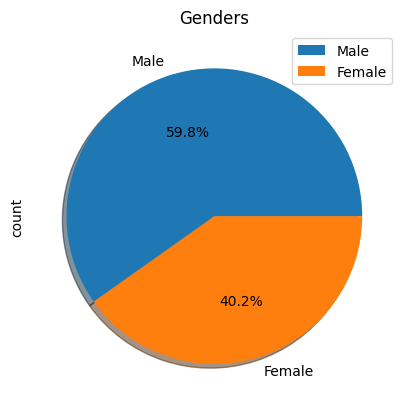

In [25]:
gender_count.plot.pie(y='count', shadow=True, autopct='%1.1f%%',labels=['Male','Female'])
plt.title('Genders')

(-1.1023152793395266,
 1.1486208785872023,
 -1.1044316339702982,
 1.1930643172770745)

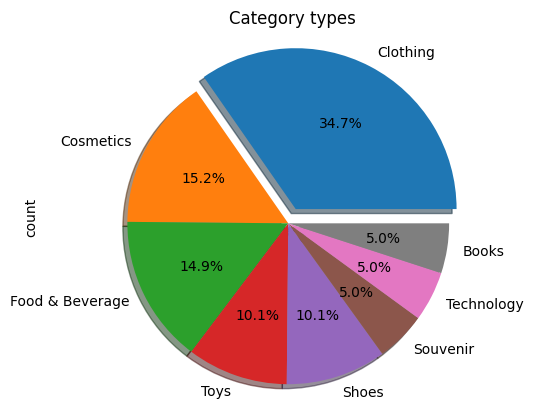

In [26]:
l=['Clothing','Cosmetics','Food & Beverage','Toys','Shoes','Souvenir','Technology','Books']
categories.plot.pie(y='count',shadow=True, autopct='%1.1f%%',labels=l, legend=0, explode=[0.1,0,0,0,0,0,0,0])
plt.title('Category types')
plt.axis('equal') 


Text(0, 0.5, 'count')

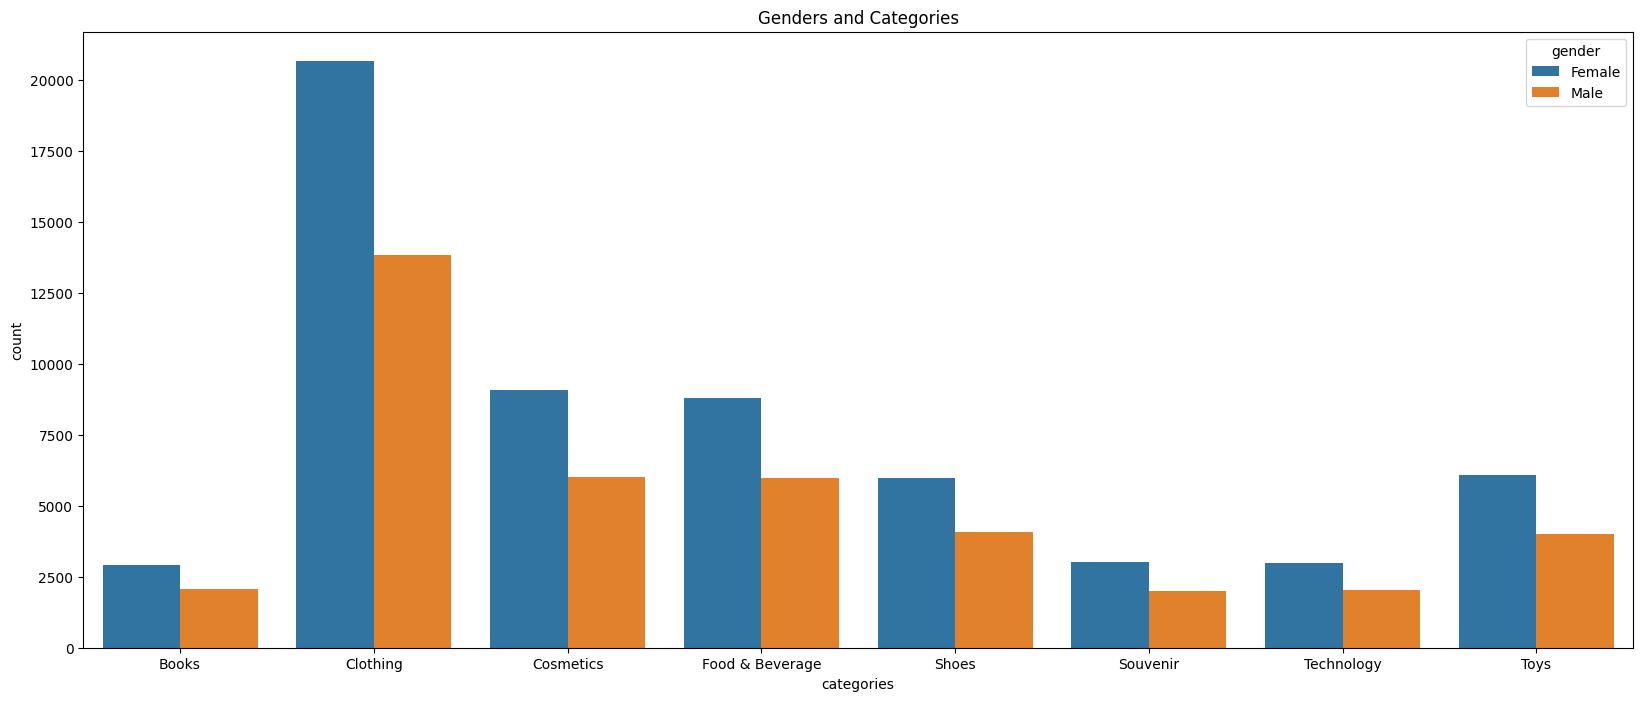

In [27]:
plt.figure(figsize=(20,8))
plt.title('Genders and Categories')
sns.barplot(x='category',y='count',data=categories_gender, hue='gender')
plt.xlabel('categories')
plt.ylabel('count')

Text(0.5, 1.0, 'Genders')

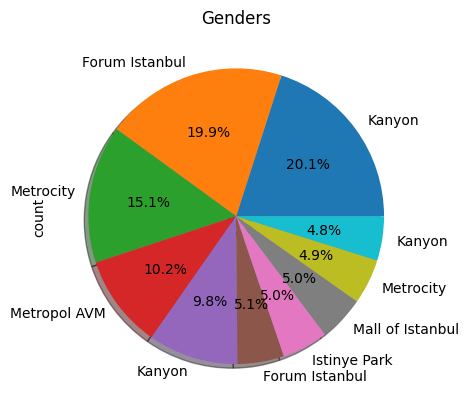

In [28]:
shopping_malls.plot.pie(y='count', shadow=True, autopct='%1.1f%%',legend=0,labels=df['shopping_mall'])
plt.title('Genders')

Text(0, 0.5, 'count')

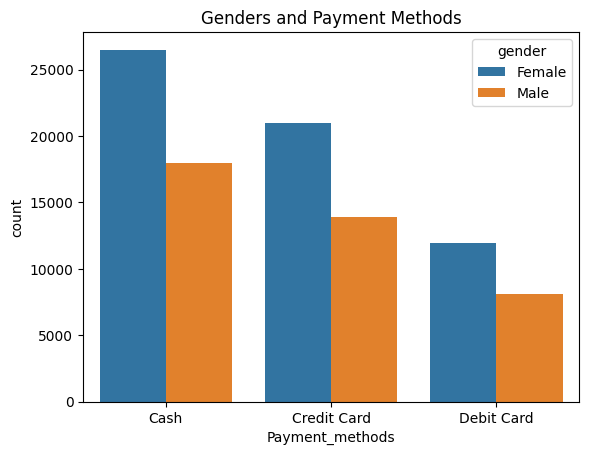

In [29]:
plt.title('Genders and Payment Methods')
sns.barplot(x='payment_method',y='count',data=payment_gender, hue='gender')
plt.xlabel('Payment_methods')
plt.ylabel('count')

Text(0, 0.5, 'Price')

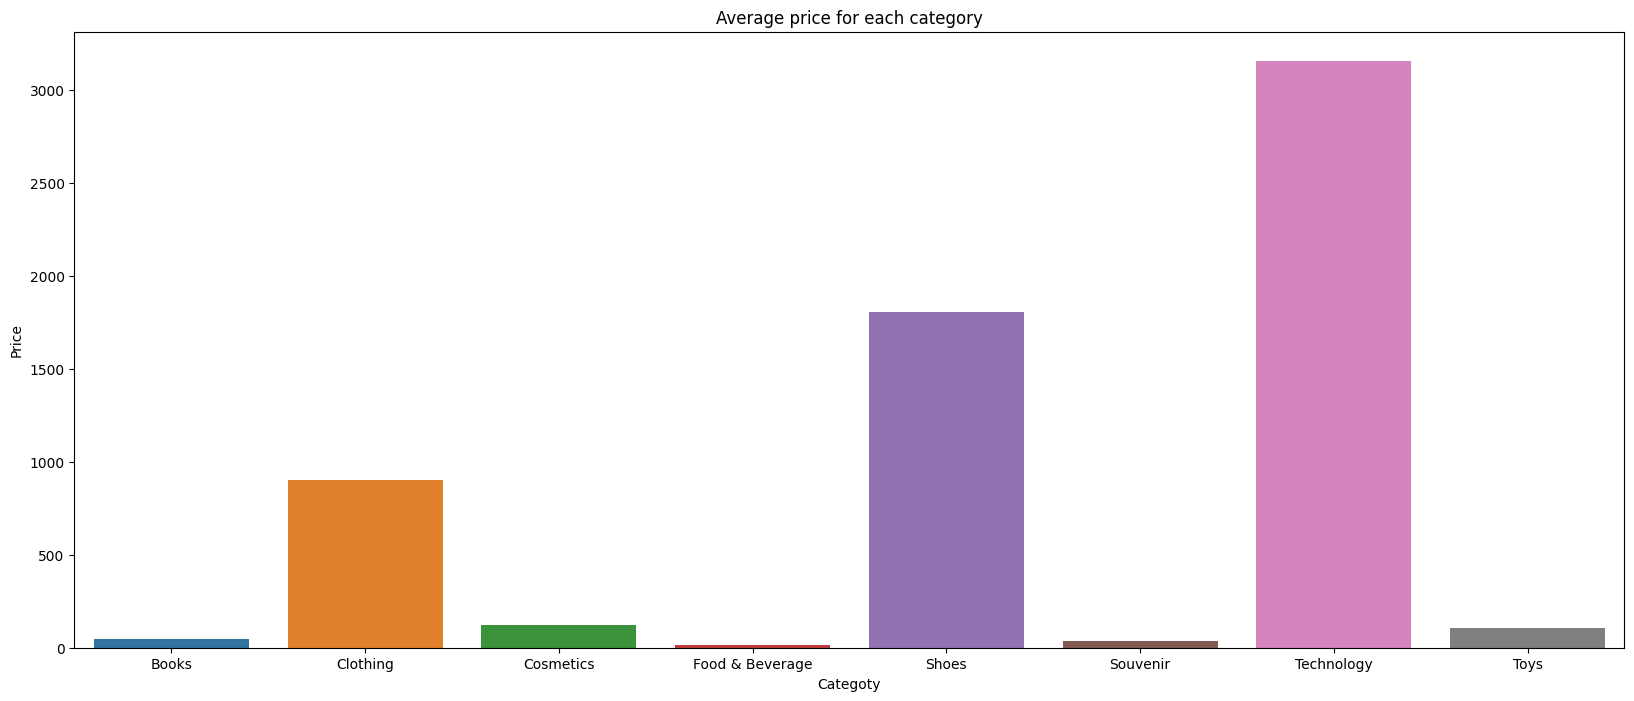

In [30]:
plt.figure(figsize=(20,8))
plt.title('Average price for each category')
sns.barplot(x='category',y='price',data=avg_price)
plt.xlabel('Categoty')
plt.ylabel('Price')